# Chapter 32: Market Structure, Competition, and Price Dispersion

This notebook reruns four worked examples from the chapter: price dispersion when some buyers compare sellers, a zero-profit bakery with excess capacity, a most-favored-customer clause, and the Diamond search paradox. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def burdett_judd(c, v, lam):
    """burdett-judd-price-dispersion: two sellers, share lam compares both prices.

    Lower support p_L = c + (v - c)(1 - lam)/(1 + lam); profit (v - c)(1 - lam)/2.
    Book: c = 15, v = 75, lam = 0.40 gives p_L = 285/7 = 40.71 and profit 18;
    lam = 0.80 gives 65/3 = 21.67 and 6.
    """
    m = v - c
    return {"p_L": c + m * (1 - lam) / (1 + lam), "profit": m * (1 - lam) / 2, "captive": (1 - lam) / 2}


def burdett_judd_survival(c, v, lam, p):
    """burdett-judd-price-dispersion: 1 - F(p) = (1 - lam)/(2 lam) (v - p)/(p - c) on [p_L, v].

    Book: c = 15, v = 75, lam = 0.40, p = 51 gives 1/2 and q(51) = 0.30 + 0.40(0.5) = 0.50.
    Returns None when p lies outside the support.
    """
    pl = burdett_judd(c, v, lam)["p_L"]
    if p < pl - 1e-12 or p > v + 1e-12:
        return None
    return (1 - lam) / (2 * lam) * (v - p) / (p - c)


def monopoly_linear(a, b, c0, c1=0.0):
    """monopolistic-competition, lerner rule: profit maximum for inverse demand p = a - b q, MC = c0 + c1 q.

    q = (a - c0) / (2b + c1). Book: a = 20, b = 0.5, c0 = 5, c1 = 0.5 gives q = 10, p = 15, MC = 10;
    a = 100, b = 0.5, c0 = 20 gives Q = 80, P = 60.
    """
    q = max(0.0, (a - c0) / (2 * b + c1))
    return {"q": q, "p": a - b * q, "mr": a - 2 * b * q, "mc": c0 + c1 * q}


def bakery_profit(a, b, c0, c1, F):
    """monopolistic-competition: profit at the MR = MC output. Book: a = 20 gives 0; a = 18 gives -56/3."""
    m = monopoly_linear(a, b, c0, c1)
    q = m["q"]
    revenue = m["p"] * q
    vc = c0 * q + c1 / 2 * q * q
    return {**m, "revenue": revenue, "vc": vc, "profit": revenue - vc - F, "atc": (F + vc) / q,
            "q_min_atc": math.sqrt(F / (c1 / 2))}


def mfc_payoff(p_old, p_bid, mc, q_new, q_protected):
    """most-favored-customer-effect: new-order contribution less the retroactive refund.

    Book: 50, 42, 30, 10, 80 gives contribution 120, refund 640, net -520, threshold 120/8 = 15;
    protected volume 10 gives net 40.
    """
    contribution = (p_bid - mc) * q_new
    cut = p_old - p_bid
    refund = cut * q_protected
    threshold = contribution / cut if cut > 0 else math.inf
    return {"contribution": contribution, "refund": refund, "net": contribution - refund, "threshold": threshold}


def diamond_deviation(c, v, n, phi, p_dev):
    """diamond-search-paradox: one seller undercuts a common price v when share phi sees all prices.

    Common profit (v - c)/n; deviator demand (1 - phi)/n + phi; deviator profit (p_dev - c) times demand.
    Book: c = 12, v = 36, n = 60, phi = 0.15, p_dev = 35 gives 0.40, 197/1200 = 0.1642, 4531/1200 = 3.78.
    """
    demand = (1 - phi) / n + phi
    common = (v - c) / n
    dev = (p_dev - c) * demand
    return {"common_profit": common, "demand": demand, "dev_profit": dev, "profitable": dev > common + 1e-12}


plt.rcParams.update(HOUSE_RC)


industrial = SimpleNamespace(burdett_judd=burdett_judd, burdett_judd_survival=burdett_judd_survival, monopoly_linear=monopoly_linear, bakery_profit=bakery_profit, mfc_payoff=mfc_payoff, diamond_deviation=diamond_deviation)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'burdett-judd-price-dispersion': {'c': 15,
                                   'v': 75,
                                   'lam': 0.4,
                                   'p_L': 40.71,
                                   'profit': 18,
                                   'p_test': 51,
                                   'survival_51': 0.5,
                                   'q_51': 0.5,
                                   'q_low': 0.7,
                                   'q_high': 0.3,
                                   'lam_2': 0.8,
                                   'p_L_2': 21.67,
                                   'profit_2': 6},
 'monopolistic-competition': {'a': 20,
                              'b': 0.5,
                              'c0': 5,
                              'c1': 0.5,
                              'F': 75,
                              'q': 10,
                              'p': 15,
                              'mc': 10,
                              'atc': 15,
                              'profit': 0,
                              'q_min_atc': 17.32,
                              'a_entry': 18,
                              'q_entry': 8.67,
                              'p_entry': 13.67,
                              'profit_entry': -18.67},
 'most-favored-customer-effect': {'p_old': 50,
                                  'mc': 30,
                                  'q_new': 10,
                                  'bid': 42,
                                  'q_protected': 80,
                                  'contribution': 120,
                                  'refund': 640,
                                  'net': -520,
                                  'threshold': 15,
                                  'net_10': 40},
 'diamond-search-paradox': {'c': 12,
                            'v': 36,
                            'n': 60,
                            'phi': 0.15,
                            'p_dev': 35,
                            'common_profit': 0.4,
                            'demand': 0.1642,
                            'dev_profit': 3.78},
 'constructed': {'burdett-judd-price-dispersion': {'lam': [0.2, 0.6]},
                 'monopolistic-competition': {'a': [19, 21]},
                 'most-favored-customer-effect': {'bid': [45, 48]},
                 'diamond-search-paradox': {'phi': [0.05, 0.3], 'p_dev': [24, 30]}}}


def dispersion_picture(lam=0.40):
    b = BV["burdett-judd-price-dispersion"]
    c, v, pt = b["c"], b["v"], b["p_test"]
    res = industrial.burdett_judd(c, v, lam)
    pl, profit, cap = res["p_L"], res["profit"], res["captive"]
    surv = industrial.burdett_judd_survival(c, v, lam, pt)
    ps = np.linspace(pl, v, 200)
    F = [1 - industrial.burdett_judd_survival(c, v, lam, p) for p in ps]
    fig, ax = new_figure()
    ax.plot(ps, F, color=PALETTE["teal"], linewidth=2.2, label="price distribution F(p)")
    ax.legend(loc="upper left", frameon=False)
    mark(ax, pl, 0, f"p_L = {num(pl)}", col="navy", dx=8, dy=10)
    mark(ax, v, 1, f"v = {v}", col="gold", dx=-8, dy=-14, ha="right", va="top")
    if surv is not None:
        mark(ax, pt, 1 - surv, f"F({pt}) = {num(1 - surv)}", col="terracotta", dx=10, dy=-6, va="top")
    else:
        vline(ax, pt, f"{pt} is below p_L", col="terracotta", ha="right", y_frac=0.6)
    ax.set_xlim(10, 80)
    ax.set_ylim(-0.08, 1.12)
    ax.set_xlabel("Price ($ per test)")
    ax.set_ylabel("Share of prices at or below p")
    metrics = {"Lower support p_L": money(pl), "Profit per seller": money(profit),
               "1 - F(51)": num(surv) if surv is not None else "undefined (51 is below the support)",
               "Expected quantity q(51)": num(cap + lam * surv) if surv is not None else "undefined (51 is not charged)"}
    m = v - c
    steps = [f"p_L = 15 + 60 x ({num(1 - lam)} / {num(1 + lam)}) = {num(pl)}",
             f"Profit = 60 x {num(1 - lam)} / 2 = {num(profit)}"]
    if surv is not None:
        q = cap + lam * surv
        steps += [f"1 - F(51) = {num(1 - lam)} / (2 x {num(lam)}) x 24 / 36 = {num(surv, 4)}",
                  f"q(51) = {num(1 - lam)} / 2 + {num(lam)} x {num(surv, 4)} = {num(q, 4)}",
                  f"(51 - 15) x {num(q, 4)} = {num(36 * q)}"]
        tail = (f"At 51 the rival is dearer with probability {num(surv, 4)}, so q(51) = {num(cap)} + {num(lam)} x "
                f"{num(surv, 4)} = {num(q, 4)} and profit is 36 x {num(q, 4)} = {num(36 * q)}, the same as at every "
                f"price in the support.")
    else:
        steps.append(f"51 is below p_L = {num(pl)}, so no seller charges 51 in this state")
        tail = f"A price of 51 lies below the lower support {num(pl)}, so no seller charges it."
    interp = (f"With a comparing share of {num(lam)}, the lower support is 15 + {m} x ({num(1 - lam)} / "
              f"{num(1 + lam)}) = {num(pl)} and each seller earns {m} x {num(1 - lam)} / 2 = {num(profit)}. {tail}")
    alt = (f"Equilibrium price distribution rising from 0 at {num(pl)} to 1 at {v} dollars when a share {num(lam)} "
           f"of buyers compares prices. Seller profit is {num(profit)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def bakery_picture(a=20):
    b = BV["monopolistic-competition"]
    r = industrial.bakery_profit(a, b["b"], b["c0"], b["c1"], b["F"])
    q, p = r["q"], r["p"]
    qs = np.linspace(2, 30, 200)
    fig, ax = new_figure()
    ax.plot(qs, a - 0.5 * qs, color=PALETTE["navy"], linewidth=2.2, label=f"demand p = {a} - 0.5q")
    ax.plot(qs, a - qs, color=PALETTE["grey"], linewidth=1.6, linestyle="dashed", label=f"MR = {a} - q")
    ax.plot(qs, 5 + 0.5 * qs, color=PALETTE["teal"], linewidth=2.0, label="MC = 5 + 0.5q")
    ax.plot(qs, 5 + 0.25 * qs + 75 / qs, color=PALETTE["gold"], linewidth=2.0, label="ATC")
    vline(ax, r["q_min_atc"], f"min ATC at {num(r['q_min_atc'])}", col="olive", ha="left", y_frac=0.12)
    mark(ax, q, p, f"q = {num(q)}, p = {num(p)}", col="terracotta", dx=-8, dy=8, ha="right")
    ax.set_xlim(0, 30)
    ax.set_ylim(0, 30)
    ax.legend(loc="upper right", frameon=False, fontsize=9.5)
    ax.set_xlabel("Loaves q (thousand)")
    ax.set_ylabel("Dollars per loaf")
    sign = "zero profit" if abs(r["profit"]) < 0.005 else ("a profit" if r["profit"] > 0 else "a loss")
    metrics = {"Output q (thousand)": num(q), "Price p": money(p), "Marginal cost": money(r["mc"]),
               "Average total cost": money(r["atc"]), "Profit ($ thousand)": num(r["profit"]),
               "Output at minimum ATC": num(r["q_min_atc"])}
    steps = [f"{a} - q = 5 + 0.5q, so q = {a - 5} / 1.5 = {num(q, 4)}",
             f"p = {a} - 0.5 x {num(q, 4)} = {num(p, 4)}",
             f"Revenue = {num(p, 4)} x {num(q, 4)} = {num(r['revenue'], 4)}",
             f"VC = 5 x {num(q, 4)} + 0.25 x {num(q, 4)}^2 = {num(r['vc'], 4)}",
             f"Profit = {num(r['revenue'], 4)} - {num(r['vc'], 4)} - 75 = {num(r['profit'])}",
             f"MC = 5 + 0.5 x {num(q, 4)} = {num(r['mc'])}, below the price {num(p)}"]
    interp = (f"MR = MC gives {a} - q = 5 + 0.5q, so q = {num(q)} thousand and p = {num(p)}. Revenue {num(r['revenue'])} "
              f"less variable cost {num(r['vc'])} and the fixed 75 leaves {sign} ({num(r['profit'])} thousand). "
              f"Price {num(p)} exceeds marginal cost {num(r['mc'])}, and output {num(q)} is below the "
              f"{num(r['q_min_atc'])} that minimizes average cost.")
    alt = (f"Residual demand with intercept {a}, marginal revenue, marginal cost and average total cost. The chosen "
           f"output {num(q)} thousand at price {num(p)} lies left of minimum average cost at {num(r['q_min_atc'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def mfc_picture(qp=80, bid=42):
    b = BV["most-favored-customer-effect"]
    r = industrial.mfc_payoff(b["p_old"], bid, b["mc"], b["q_new"], qp)
    cut = b["p_old"] - bid
    fig, ax = new_figure()
    bar_compare(ax, ["new-order contribution", "retroactive refund", "net payoff"],
                [r["contribution"], -r["refund"], r["net"]], colors=["teal", "terracotta", "navy"],
                value_labels=[num(r["contribution"], 0), num(-r["refund"], 0), num(r["net"], 0)],
                ylabel="$ thousand", xlabel="Payoff component")
    verdict = ("worth winning" if r["net"] > 0 else
               ("exactly break-even, so the seller is indifferent" if r["net"] == 0 else "not worth winning"))
    metrics = {"Contribution ($ thousand)": num(r["contribution"], 0), "Refund ($ thousand)": num(r["refund"], 0),
               "Net payoff ($ thousand)": num(r["net"], 0), "Threshold protected volume": num(r["threshold"], 2),
               "Decision": "Bid" if r["net"] > 0 else ("Indifferent" if r["net"] == 0 else "Do not bid")}
    steps = [f"Contribution = ({bid} - 30) x 10 = {num(r['contribution'], 0)}",
             f"Refund = (50 - {bid}) x {qp} = {num(r['refund'], 0)}",
             f"Net = {num(r['contribution'], 0)} - {num(r['refund'], 0)} = {num(r['net'], 0)}",
             f"Threshold = {num(r['contribution'], 0)} / {cut} = {num(r['threshold'])}"]
    interp = (f"The new order adds ({bid} - 30) x 10 = {num(r['contribution'], 0)} thousand. The clause refunds "
              f"{cut} on {qp} thousand protected cartons, {num(r['refund'], 0)} thousand, so the net is "
              f"{num(r['net'], 0)} thousand and the order is {verdict}. Discounting pays only while protected volume "
              f"is below {num(r['contribution'], 0)} / {cut} = {num(r['threshold'])} thousand.")
    alt = (f"Bars: new-order contribution {num(r['contribution'], 0)}, refund {num(r['refund'], 0)} shown as a negative, "
           f"and net payoff {num(r['net'], 0)} thousand dollars for a bid of {bid} with {qp} thousand protected cartons.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def diamond_picture(phi=0.15, pd=35):
    b = BV["diamond-search-paradox"]
    c, v, n = b["c"], b["v"], b["n"]
    r = industrial.diamond_deviation(c, v, n, phi, pd)
    fig, ax = new_figure()
    bar_compare(ax, ["common price 36", f"deviate to {pd}"], [r["common_profit"], r["dev_profit"]],
                colors=["grey", "teal" if r["profitable"] else "terracotta"],
                value_labels=[money(r["common_profit"]), money(r["dev_profit"])],
                ylabel="Profit per unit mass ($)", xlabel="Pricing choice")
    verdict = "profitable" if r["profitable"] else "not profitable"
    metrics = {"Common-price profit": money(r["common_profit"]), "Deviator demand": num(r["demand"], 4),
               "Deviator profit": money(r["dev_profit"]), "Undercutting": verdict.capitalize()}
    steps = [f"Common profit = 24 x (1/60) = {num(r['common_profit'])}",
             f"Demand = {num(1 - phi)} / 60 + {num(phi)} = {num(r['demand'], 6)}",
             f"Deviator profit = ({pd} - 12) x {num(r['demand'], 6)} = {num(r['dev_profit'], 3)}"]
    why = ("No buyer sees the cut, so the deviator keeps 1/60 of buyers at a lower margin." if phi == 0
           else f"The cut wins every informed buyer, a share {num(phi)}, on top of its captive share.")
    interp = (f"At the common price each service earns 24 / 60 = {num(r['common_profit'])}. Cutting to {pd} gives "
              f"demand {num(1 - phi)} / 60 + {num(phi)} = {num(r['demand'], 6)} and profit ({pd} - 12) x "
              f"{num(r['demand'], 6)} = {num(r['dev_profit'], 3)}, so undercutting is {verdict}. {why}")
    alt = (f"Bars comparing profit at the common price 36, {money(r['common_profit'])}, with profit after cutting to "
           f"{pd}, {money(r['dev_profit'])}, when a share {num(phi)} of buyers sees every price.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Burdett-Judd price dispersion: how comparison shoppers set the price floor

Two labs have cost \$15 and buyers value the test at \$75; a share $\lambda=0.40$ compares both.

$$p_L=15+60\left(\frac{0.60}{1.40}\right)=\frac{285}{7}\approx\$40.71, \qquad \bar\pi=\frac{(75-15)(0.60)}{2}=\$18$$

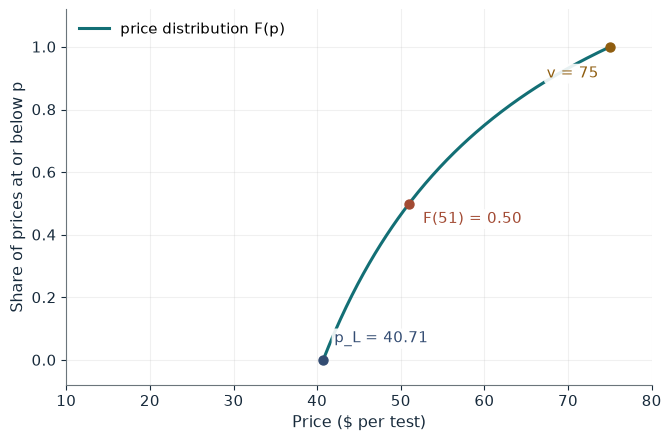

Lower support p_L        $40.71
Profit per seller        $18.00
1 - F(51)                0.50
Expected quantity q(51)  0.50

Worked steps:
  1. p_L = 15 + 60 x (0.60 / 1.40) = 40.71
  2. Profit = 60 x 0.60 / 2 = 18.00
  3. 1 - F(51) = 0.60 / (2 x 0.40) x 24 / 36 = 0.5000
  4. q(51) = 0.60 / 2 + 0.40 x 0.5000 = 0.5000
  5. (51 - 15) x 0.5000 = 18.00

With a comparing share of 0.40, the lower support is 15 + 60 x (0.60 / 1.40) = 40.71 and each seller earns 60 x 0.60 / 2 = 18.00. At 51 the rival is dearer with probability 0.5000, so q(51) = 0.30 + 0.40 x 0.5000 = 0.5000 and profit is 36 x 0.5000 = 18.00, the same as at every price in the support.


In [2]:
show(dispersion_picture(lam=0.40))

Change one input, `lam`, and hold the others at the book's values:

In [3]:
sweep(dispersion_picture, 'lam', [0.2, 0.4, 0.6, 0.8], {}, ['Lower support p_L', 'Profit per seller', '1 - F(51)'])

lam | Lower support p_L | Profit per seller | 1 - F(51)
0.2 | $55.00 | $24.00 | undefined (51 is below the support)
0.4 | $40.71 | $18.00 | 0.50
0.6 | $30.00 | $12.00 | 0.22
0.8 | $21.67 | $6.00 | 0.08


Every price between 40.71 and 75 earns the same \$18. When the comparing share rises to 0.80 the floor falls to 21.67 and profit to \$6; at 0.20 the floor is 55, so a price of 51 is never charged.

## 2. Monopolistic competition: zero profit, excess capacity

The bakery faces $p=20-0.5q$ and $VC(q)=5q+0.25q^2$ with a fixed cost of 75 (thousand).

$$MR=20-q,\qquad MC=5+0.5q, \qquad ATC(q)=5+0.25q+\frac{75}{q}$$

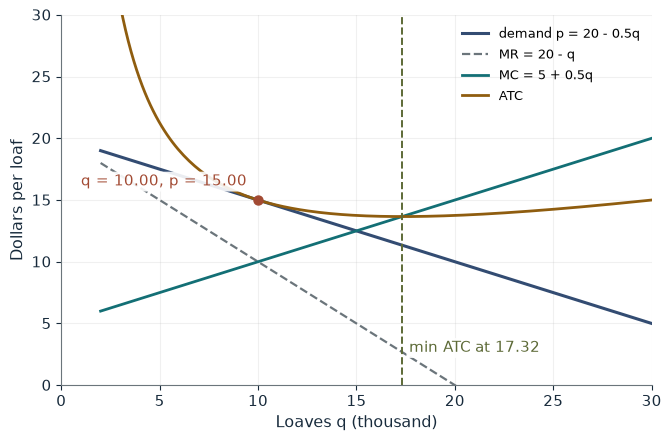

Output q (thousand)    10.00
Price p                $15.00
Marginal cost          $10.00
Average total cost     $15.00
Profit ($ thousand)    0.00
Output at minimum ATC  17.32

Worked steps:
  1. 20 - q = 5 + 0.5q, so q = 15 / 1.5 = 10.0000
  2. p = 20 - 0.5 x 10.0000 = 15.0000
  3. Revenue = 15.0000 x 10.0000 = 150.0000
  4. VC = 5 x 10.0000 + 0.25 x 10.0000^2 = 75.0000
  5. Profit = 150.0000 - 75.0000 - 75 = 0.00
  6. MC = 5 + 0.5 x 10.0000 = 10.00, below the price 15.00

MR = MC gives 20 - q = 5 + 0.5q, so q = 10.00 thousand and p = 15.00. Revenue 150.00 less variable cost 75.00 and the fixed 75 leaves zero profit (0.00 thousand). Price 15.00 exceeds marginal cost 10.00, and output 10.00 is below the 17.32 that minimizes average cost.


In [4]:
show(bakery_picture(a=20))

Change one input, `a`, and hold the others at the book's values:

In [5]:
sweep(bakery_picture, 'a', [18, 19, 20, 21], {}, ['Output q (thousand)', 'Price p', 'Profit ($ thousand)'])

a | Output q (thousand) | Price p | Profit ($ thousand)
18 | 8.67 | $13.67 | -18.67
19 | 9.33 | $14.33 | -9.67
20 | 10.00 | $15.00 | 0.00
21 | 10.67 | $15.67 | 10.33


At the book's intercept profit is zero while price 15 exceeds marginal cost 10 and output 10 is below the 17.32 that minimizes average cost. Entry that lowers the intercept to 18 produces a loss of 18.67.

## 3. Most-favored-customer effect: a clause flips a bid

Past buyers paid \$50, marginal cost is \$30, the new order is 10 thousand and the winning bid is \$42.

$$(42-30)(10)>(50-42)Q^P, \qquad Q^P<\frac{120}{8}=15$$

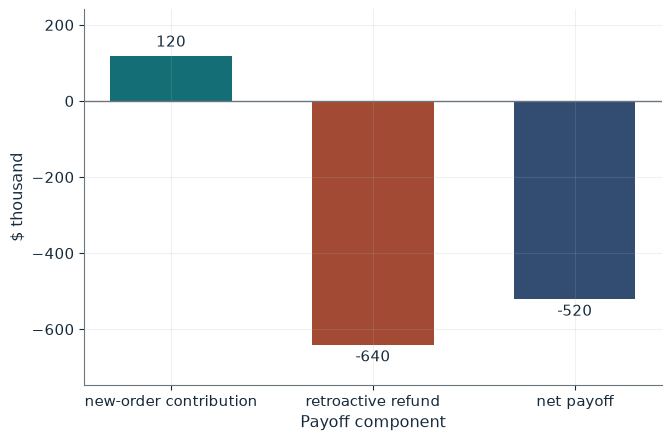

Contribution ($ thousand)   120
Refund ($ thousand)         640
Net payoff ($ thousand)     -520
Threshold protected volume  15.00
Decision                    Do not bid

Worked steps:
  1. Contribution = (42 - 30) x 10 = 120
  2. Refund = (50 - 42) x 80 = 640
  3. Net = 120 - 640 = -520
  4. Threshold = 120 / 8 = 15.00

The new order adds (42 - 30) x 10 = 120 thousand. The clause refunds 8 on 80 thousand protected cartons, 640 thousand, so the net is -520 thousand and the order is not worth winning. Discounting pays only while protected volume is below 120 / 8 = 15.00 thousand.


In [6]:
show(mfc_picture(qp=80, bid=42))

Change one input, `qp`, and hold the others at the book's values:

In [7]:
sweep(mfc_picture, 'qp', [0, 10, 15, 80], {'bid': 42}, ['Refund ($ thousand)', 'Net payoff ($ thousand)', 'Decision'])

qp | Refund ($ thousand) | Net payoff ($ thousand) | Decision
0 | 0 | 120 | Bid
10 | 80 | 40 | Bid
15 | 120 | 0 | Indifferent
80 | 640 | -520 | Do not bid


With 80 thousand protected cartons the refund of 640 swamps the 120 contribution. Coverage of 10 thousand leaves a net of 40, and 15 thousand is the break-even point.

## 4. Diamond search paradox: informed buyers break the monopoly price

Sixty services have cost \$12 and customers value the task at \$36. A share 0.15 sees every price.

$$\frac{0.85}{60}+0.15=\frac{197}{1200}\approx0.1642, \qquad (35-12)\frac{197}{1200}=\frac{4531}{1200}\approx\$3.78$$

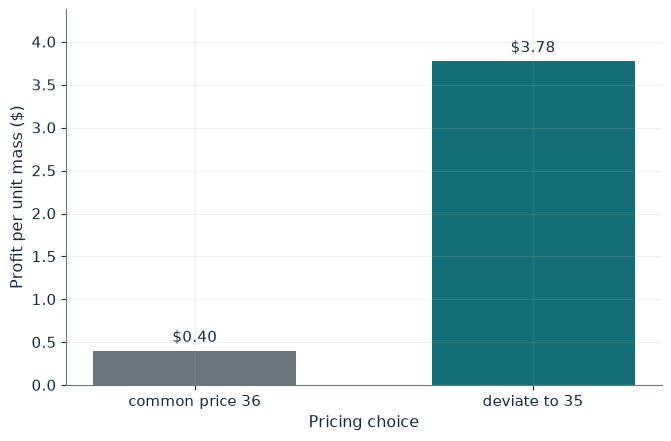

Common-price profit  $0.40
Deviator demand      0.1642
Deviator profit      $3.78
Undercutting         Profitable

Worked steps:
  1. Common profit = 24 x (1/60) = 0.40
  2. Demand = 0.85 / 60 + 0.15 = 0.164167
  3. Deviator profit = (35 - 12) x 0.164167 = 3.776

At the common price each service earns 24 / 60 = 0.40. Cutting to 35 gives demand 0.85 / 60 + 0.15 = 0.164167 and profit (35 - 12) x 0.164167 = 3.776, so undercutting is profitable. The cut wins every informed buyer, a share 0.15, on top of its captive share.


In [8]:
show(diamond_picture(phi=0.15, pd=35))

Change one input, `phi`, and hold the others at the book's values:

In [9]:
sweep(diamond_picture, 'phi', [0, 0.05, 0.15, 0.3], {'pd': 35}, ['Deviator demand', 'Deviator profit', 'Undercutting'])

phi | Deviator demand | Deviator profit | Undercutting
0 | 0.0167 | $0.38 | Not profitable
0.05 | 0.0658 | $1.51 | Profitable
0.15 | 0.1642 | $3.78 | Profitable
0.3 | 0.3117 | $7.17 | Profitable


Without informed buyers a cut to 35 earns only 0.38, below 0.40, so the common price of 36 survives. Any positive informed share makes the cut visible and profitable.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

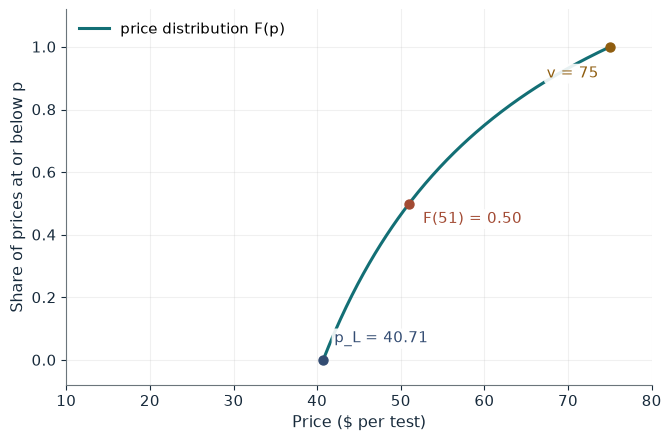

Lower support p_L        $40.71
Profit per seller        $18.00
1 - F(51)                0.50
Expected quantity q(51)  0.50

Worked steps:
  1. p_L = 15 + 60 x (0.60 / 1.40) = 40.71
  2. Profit = 60 x 0.60 / 2 = 18.00
  3. 1 - F(51) = 0.60 / (2 x 0.40) x 24 / 36 = 0.5000
  4. q(51) = 0.60 / 2 + 0.40 x 0.5000 = 0.5000
  5. (51 - 15) x 0.5000 = 18.00

With a comparing share of 0.40, the lower support is 15 + 60 x (0.60 / 1.40) = 40.71 and each seller earns 60 x 0.60 / 2 = 18.00. At 51 the rival is dearer with probability 0.5000, so q(51) = 0.30 + 0.40 x 0.5000 = 0.5000 and profit is 36 x 0.5000 = 18.00, the same as at every price in the support.


In [10]:
show(dispersion_picture(lam=0.40))

## Practice

**1.** With a comparing share of 0.60, what is the lowest price in the support and each seller's profit?

<details><summary>Answer</summary>

p_L = 15 + 60 x (0.40 / 1.60) = 30; profit = 60 x 0.40 / 2 = 12.

</details>

**2.** At a demand intercept of 21, what output and profit does the bakery reach?

<details><summary>Answer</summary>

21 - q = 5 + 0.5q gives q = 10.67 and p = 15.67; profit = 167.11 - 81.78 - 75 = 10.33 thousand.

</details>

**3.** At a bid of 45 with 80 thousand protected cartons, what is the net payoff?

<details><summary>Answer</summary>

(45 - 30) x 10 = 150; refund (50 - 45) x 80 = 400; net = 150 - 400 = -250 thousand.

</details>